# Neural exploration during BCI decoder remapping (`mouse_0403L`)

**Question: how does the animal explore neural state space to find and control a new decoder axis?**

Every remapping day has the same structure — an **intuitive** block (factor 2) → uncued rotation to the
**new** axis (factor 3) → **washout** back to the intuitive axis (factor 2). This notebook studies two
distinct phenomena:

1. **Discovery (first remapping day).** How does population activity search for the new axis before
   control is achieved?
2. **Switching (later days).** How does the animal notice the intuitive axis stopped working and
   switch to the already-learned new axis?

Tools come from `utilities/neural_analysis_utils.py` (`na`); analysis flow and plotting stay open in
the notebook. Preprocessing matches `neural_analysis.ipynb`: non-overlapping **5-frame (~166 ms) bins**
→ 6 Hz, per-neuron z-score. Decoder weights are never used — `factor_to_use` is only a block label.

### Method note: how "the intuitive solution" and "the new solution" are defined
Both are **neural templates**, not decoder weights:
* `T_int` = mean population state over the **last 0.5 s of successful trials in the pre-rotation block**.
* `T_new` = mean population state over the last 0.5 s of successful trials in the **late half of the new
  block** (well after any transition).

Endpoint (last-1 s) states separate the two solutions far better than whole-trial means
(d′ ≈ 4.3–5.9 vs 3.3–3.5), because the endpoint *is* the rewarded state. Templates come from epochs
**outside** the transition being measured, so switch-timing estimates are not circular.

Each state is then described by **two** numbers (Section 5): **`p`**, its position along the line
`T_int → T_new` (**0 = intuitive solution, 1 = new solution**), and **`resid`**, its perpendicular
distance from that line (**large = close to neither solution**). Two simpler readouts were tried and
rejected — a 1-D projection alone (baseline activity also projects near the "new" end, so it
cannot separate "new solution" from "not a solution") and the scale-free index
`(d_int − d_new)/(d_int + d_new)` (too insensitive in 468-D). The `(p, resid)` version passes two
independent controls: washout endpoints fall back to `p ≈ 0`, and baseline activity sits at
intermediate `p` with the largest `resid`.

### Sections
1 setup · 2 behavioural anatomy of the switch · 3 **continuous PCA trajectory through remapping** ·
4 **animation** · 5 solution-space geometry (discovery vs switching) · 6 exploration geometry
(speed / spread / dimensionality) · 7 perseveration & abandonment on day 0 · 8 within-trial switch
dynamics on later days · 9 washout: growing interference · 10 synthesis

## 1 · Setup, block segmentation, and solution templates

In [1]:
%matplotlib inline
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib import animation
import seaborn as sns
from scipy.stats import spearmanr, wilcoxon, mannwhitneyu
from scipy.ndimage import gaussian_filter1d

REPO = Path.cwd(); sys.path.insert(0, str(REPO / "utilities"))
import importlib, neural_analysis_utils as na; importlib.reload(na)
import richfile as rfs; na.register_richfile_types(rfs)
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k): return x

# ---------------- CONFIG ----------------
SR = 30; BIN_SIZE_FRAMES = 5; SRB = SR / BIN_SIZE_FRAMES     # 6 Hz binned
DATA_ROOT = Path(r"C:\Data\datasets\bmi_packets\bmi_packets")
MOUSE = "mouse_0403L"
OUT = REPO / "output" / MOUSE / "exploration"; OUT.mkdir(parents=True, exist_ok=True)

ENDPOINT_SEC = 0.5      # last-.5s window defining a trial's "solution" state
K_GEOM = 20             # PCA dims for exploration geometry
WIN_SEC, STEP_SEC = 30.0, 10.0
MISS_WINDOW_SEC = 20.0  # max trial duration in this dataset
TRAJ_SMOOTH_SIGMA_BINS = 2.0   # DISPLAY-ONLY smoothing of the drawn path (0 = off); 2 bins ~ 330 ms
USE_CACHE = True
TAG = f"b{BIN_SIZE_FRAMES}_e{ENDPOINT_SEC}_k{K_GEOM}"
sns.set_context("notebook")

r = na.open_mouse(rfs, DATA_ROOT, MOUSE)
days = na.get_day_list(r)
def _facs(d):
    t = na.get_true_bmi_trials(na.get_trials_df(r, d)); return np.unique(t.factor[np.isfinite(t.factor)])
REMAP_DAYS = [d for d in days if _facs(d).size > 1]
print(f"{MOUSE}: {len(REMAP_DAYS)} remapping days -> {REMAP_DAYS[0]} ... {REMAP_DAYS[-1]}")

mouse_0403L: 15 remapping days -> 20230725 ... 20230808


In [2]:
def load_day(day):
    '''Binned+z-scored session, trials in bin units, reward frames in bins, and the 3 blocks.'''
    X = na.bin_and_zscore(na.load_neural(r, day), BIN_SIZE_FRAMES)
    trials = na.bin_trials(na.get_true_bmi_trials(na.get_trials_df(r, day)), BIN_SIZE_FRAMES)
    rew = na.bin_frames(na.get_active_reward_frames(r, day), BIN_SIZE_FRAMES)
    blocks = na.segment_factor_blocks(trials)
    return X, trials, rew, blocks, X.shape[1]

def ok_trials(trials, idxs):
    return [i for i in idxs if np.isfinite(trials.start[i]) and np.isfinite(trials.end[i])
            and trials.end[i] > trials.start[i]]

def block_trials(trials, b, success=None):
    idx = list(range(b.first_trial, b.last_trial + 1))
    if success is not None:
        idx = [i for i in idx if trials.success[i] == success]
    return ok_trials(trials, idx)

def endpoint_states(X, trials, idxs, endsec=ENDPOINT_SEC):
    '''Mean population state over the last `endsec` of each trial -> (n_trials, n_neurons).'''
    w = max(int(round(endsec * SRB)), 1); out = []
    for i in idxs:
        s, e = max(int(round(trials.start[i])), 0), min(int(round(trials.end[i])), X.shape[1])
        if e > s: out.append(X[:, max(e - w, s):e].mean(1))
    return np.array(out) if out else np.empty((0, X.shape[0]))

def solution_templates(X, trials, blocks):
    '''T_int from pre-rotation successes; T_new from the LATE half of new-block successes.'''
    b_int, b_new, _ = blocks
    I = block_trials(trials, b_int, success=1)
    N = block_trials(trials, b_new, success=1); N = N[len(N) // 2:]
    if len(I) < 5 or len(N) < 5: return None
    T_int = endpoint_states(X, trials, I).mean(0)
    T_new = endpoint_states(X, trials, N).mean(0)
    return T_int, T_new, float(np.linalg.norm(T_new - T_int))

def solution_index(states, T_int, T_new):
    '''(d_int - d_new)/(d_int + d_new): <0 intuitive, >0 new, ~0 neither. Also returns raw distances.'''
    if len(states) == 0: return np.array([]), np.array([]), np.array([])
    d_i = np.linalg.norm(states - T_int, axis=1); d_n = np.linalg.norm(states - T_new, axis=1)
    return (d_i - d_n) / (d_i + d_n), d_i, d_n

print("helpers ready")

helpers ready


## 2 · Behavioural anatomy of the switch

Before any neural analysis: what does the animal actually *do* when the axis rotates? Per remapping
day we measure, for the new block and for the washout block, the **latency to the first success** and
the **number of failed trials before it**, plus block hit rate. This separates *discovery* from
*switching* and sets the timescale everything else must explain.

In [3]:
def behaviour_row(day, di):
    X, trials, rew, blocks, T = load_day(day)
    b_int, b_new, b_wash = blocks
    def first_success(b):
        for k, i in enumerate(range(b.first_trial, b.last_trial + 1)):
            if trials.success[i] == 1 and np.isfinite(trials.end[i]):
                return (trials.end[i] - b.start_frame) / SRB, k
        return np.nan, np.nan
    lat_new, k_new = first_success(b_new); lat_w, k_w = first_success(b_wash)
    hit = lambda b: float(np.nanmean(trials.success[b.first_trial:b.last_trial + 1]))
    return dict(day=day, remap_day=di,
                lat_new=lat_new, nfail_before_new=k_new, hit_new=hit(b_new),
                lat_wash=lat_w, nfail_before_wash=k_w, hit_wash=hit(b_wash),
                hit_int=hit(b_int), n_new=b_new.n_trials, n_wash=b_wash.n_trials,
                remap_min=b_new.start_frame / SRB / 60, wash_min=b_wash.start_frame / SRB / 60)

beh_fp = OUT / f"behaviour_{TAG}.csv"
if USE_CACHE and beh_fp.exists():
    beh = pd.read_csv(beh_fp); beh["day"] = beh["day"].astype(str)
else:
    beh = pd.DataFrame([behaviour_row(d, i) for i, d in enumerate(tqdm(REMAP_DAYS, desc="behaviour"))])
    beh.to_csv(beh_fp, index=False)
display(beh.round(2))

,day,remap_day,lat_new,nfail_before_new,hit_new,lat_wash,nfail_before_wash,hit_wash,hit_int,n_new,n_wash,remap_min,wash_min
0,20230725,0,70.53,2,0.74,6.60,0,1.00,1.00,182,34,11.44,71.64
1,20230726,1,6.27,0,0.88,0.47,0,0.76,1.00,237,26,11.46,71.13
2,20230727,2,35.43,1,0.96,28.83,1,0.86,1.00,242,35,11.01,57.76
3,20230728,3,1.43,0,0.99,8.60,0,1.00,1.00,232,50,11.34,48.45
4,20230729,4,5.67,0,0.98,7.87,0,0.98,0.92,244,46,11.03,55.98
5,20230730,5,9.30,0,1.00,0.80,0,1.00,0.96,243,59,11.09,50.14
6,20230731,6,1.37,0,1.00,14.47,0,0.78,1.00,239,37,11.21,42.65
7,20230801,7,6.53,0,1.00,14.23,0,0.74,0.96,242,31,11.38,52.01
8,20230802,8,2.10,0,0.99,13.67,0,0.96,1.00,245,47,11.24,52.23
9,20230803,9,1.90,0,0.99,12.43,0,0.76,0.96,246,33,11.22,55.02


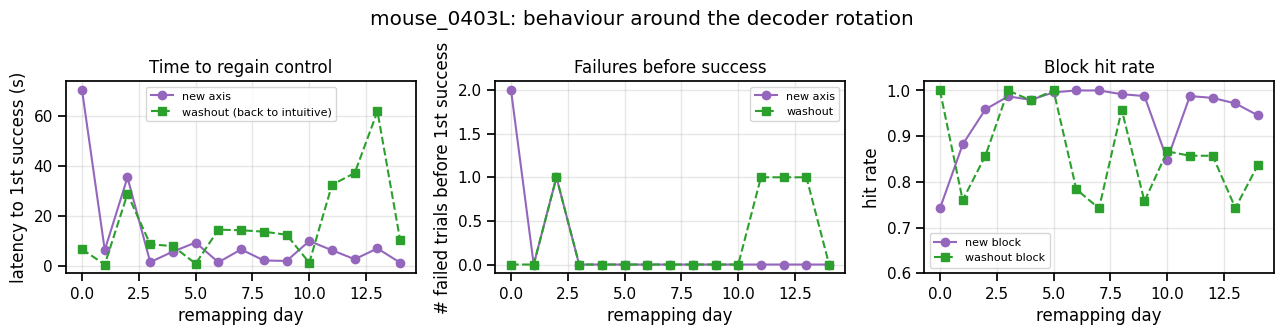

Day 0:  latency to new-axis success = 70.5 s after 2 failed trials; hit=0.74
Later:  latency = 6.9 s (median 5.9) after 0.07 failed trials; hit=0.97
  lat_new    vs remap day: Spearman r=-0.36 p=0.187
  lat_wash   vs remap day: Spearman r=+0.52 p=0.044
  hit_wash   vs remap day: Spearman r=-0.41 p=0.129
READ: day 0 is a genuine SEARCH (~70 s, several failures). From day 1 on the animal is essentially correct on the FIRST new-axis trial -> a SWITCH, not re-learning. Meanwhile washout gets progressively harder: the new solution becomes dominant (see Section 9).


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].plot(beh.remap_day, beh.lat_new, "o-", color="tab:purple", label="new axis")
axes[0].plot(beh.remap_day, beh.lat_wash, "s--", color="tab:green", label="washout (back to intuitive)")
axes[0].set(xlabel="remapping day", ylabel="latency to 1st success (s)", title="Time to regain control"); axes[0].legend(fontsize=8)
axes[1].plot(beh.remap_day, beh.nfail_before_new, "o-", color="tab:purple", label="new axis")
axes[1].plot(beh.remap_day, beh.nfail_before_wash, "s--", color="tab:green", label="washout")
axes[1].set(xlabel="remapping day", ylabel="# failed trials before 1st success", title="Failures before success"); axes[1].legend(fontsize=8)
axes[2].plot(beh.remap_day, beh.hit_new, "o-", color="tab:purple", label="new block")
axes[2].plot(beh.remap_day, beh.hit_wash, "s--", color="tab:green", label="washout block")
axes[2].set(xlabel="remapping day", ylabel="hit rate", title="Block hit rate", ylim=(0.6, 1.02)); axes[2].legend(fontsize=8)
for a in axes: a.grid(alpha=0.3)
fig.suptitle(f"{MOUSE}: behaviour around the decoder rotation")
fig.tight_layout(); fig.savefig(OUT / "A2_behaviour.png", dpi=150); plt.show()

d0 = beh[beh.remap_day == 0].iloc[0]; later = beh[beh.remap_day > 0]
print(f"Day 0:  latency to new-axis success = {d0.lat_new:.1f} s after {d0.nfail_before_new:.0f} failed trials; hit={d0.hit_new:.2f}")
print(f"Later:  latency = {later.lat_new.mean():.1f} s (median {later.lat_new.median():.1f}) after "
      f"{later.nfail_before_new.mean():.2f} failed trials; hit={later.hit_new.mean():.2f}")
for c in ["lat_new", "lat_wash", "hit_wash"]:
    x = beh[["remap_day", c]].dropna(); rho, p = spearmanr(x.remap_day, x[c])
    print(f"  {c:10s} vs remap day: Spearman r={rho:+.2f} p={p:.3f}")
print("\
READ: day 0 is a genuine SEARCH (~70 s, several failures). From day 1 on the animal is "
      "essentially correct on the FIRST new-axis trial -> a SWITCH, not re-learning. Meanwhile washout "
      "gets progressively harder: the new solution becomes dominant (see Section 9).")

## 3 · Continuous neural trajectory through the rotation  *(core visualisation)*

A single PCA space is fitted to **all timepoints in the plotted window** (not per condition), and the
continuous population trajectory is drawn through it, coloured by behavioural state
(**correct trial**, **incorrect trial**, **inter-trial/baseline**) with events marked: trial starts,
rewards, **rotation onset**, **washout onset**, and the solution templates `T_int` / `T_new`.

In [5]:
STATE_COLORS = {na.STATE_ITI: "0.72", na.STATE_CORRECT: "tab:blue", na.STATE_INCORRECT: "tab:red"}
STATE_LABEL = {na.STATE_ITI: "inter-trial / baseline", na.STATE_CORRECT: "correct trial", na.STATE_INCORRECT: "incorrect trial"}

def trajectory_window(day, t0_min, t1_min, k=6):
    '''Everything needed to draw/animate a window: projected trajectory, labels, events, solution index.'''
    X, trials, rew, blocks, T = load_day(day)
    b_int, b_new, b_wash = blocks
    w0, w1 = int(max(t0_min * 60 * SRB, 0)), int(min(t1_min * 60 * SRB, T))
    sub = na.fit_subspace(X[:, w0:w1].T, k)          # ONE PCA space for the whole window
    P = sub.project(X[:, w0:w1].T)
    lab = na.label_timepoints(trials, T, sr=SRB)[w0:w1]
    tmin = (np.arange(w0, w1) - b_new.start_frame) / SRB / 60      # time relative to rotation
    tpl = solution_templates(X, trials, blocks)
    sol = np.full(w1 - w0, np.nan)
    tpl_proj = None
    if tpl is not None:
        T_int, T_new, L = tpl
        d_i = np.linalg.norm(X[:, w0:w1].T - T_int, axis=1); d_n = np.linalg.norm(X[:, w0:w1].T - T_new, axis=1)
        sol = (d_i - d_n) / (d_i + d_n)
        tpl_proj = (sub.project(T_int[None, :])[0], sub.project(T_new[None, :])[0])
    ev = dict(
        trial_starts=[int(s) - w0 for s in trials.start if np.isfinite(s) and w0 <= s < w1],
        rewards=[int(f) - w0 for f in rew if np.isfinite(f) and w0 <= f < w1],
        remap=int(b_new.start_frame) - w0 if w0 <= b_new.start_frame < w1 else None,
        wash=int(b_wash.start_frame) - w0 if w0 <= b_wash.start_frame < w1 else None)
    return dict(P=P, lab=lab, tmin=tmin, sol=sol, ev=ev, tpl_proj=tpl_proj, w0=w0, w1=w1,
                remap_min=b_new.start_frame / SRB / 60, wash_min=b_wash.start_frame / SRB / 60)

def smooth_path(P, sigma_bins=TRAJ_SMOOTH_SIGMA_BINS):
    '''DISPLAY-ONLY low-pass along time, applied to the PROJECTED path (never to the neural data).

    A Gaussian filter over time is a weighted average of neighbouring real states, so the drawn curve
    stays inside the local hull of the trajectory -- it cannot visit places the population never went.
    It does damp fast excursions, so it is used ONLY for drawing: every quantitative measure in this
    notebook (speed, path length, p / resid, all statistics) is computed on the unsmoothed 6 Hz data,
    and the raw path is always drawn faintly underneath.'''
    if not sigma_bins: return P
    return gaussian_filter1d(np.asarray(P, float), sigma=float(sigma_bins), axis=0, mode="nearest")

def draw_trajectory(W, pcs=(0, 1), ax=None, lw=1.6, alpha=0.9, title="", legend=True,
                    smooth_sigma=TRAJ_SMOOTH_SIGMA_BINS, show_raw=True):
    P, lab, ev = W["P"], W["lab"], W["ev"]
    a, b = pcs
    if ax is None: _, ax = plt.subplots(figsize=(6, 5))
    raw = P[:, [a, b]]
    pts = smooth_path(P, smooth_sigma)[:, [a, b]]
    if show_raw and smooth_sigma:
        ax.plot(raw[:, 0], raw[:, 1], color="0.86", lw=0.4, alpha=0.85, zorder=0)   # unsmoothed reference
    seg = np.stack([pts[:-1], pts[1:]], axis=1)
    cols = [STATE_COLORS.get(int(s), "0.7") for s in lab[:-1]]
    ax.add_collection(LineCollection(seg, colors=cols, linewidths=lw, alpha=alpha))
    ax.scatter(*pts[ev["trial_starts"]].T, s=9, c="k", marker="|", zorder=3, label="trial start")
    if ev["rewards"]: ax.scatter(*pts[ev["rewards"]].T, s=14, facecolor="none", edgecolor="tab:green", lw=0.7, zorder=4, label="reward")
    if ev["remap"] is not None: ax.scatter(*pts[ev["remap"]], s=200, marker="*", color="crimson", zorder=6, label="rotation onset")
    if ev["wash"] is not None: ax.scatter(*pts[ev["wash"]], s=200, marker="*", color="darkorange", zorder=6, label="washout onset")
    if W["tpl_proj"] is not None:
        ti, tn = W["tpl_proj"]
        ax.scatter(ti[a], ti[b], s=170, marker="X", color="navy", edgecolor="w", zorder=7, label="$T_{int}$ (intuitive solution)")
        ax.scatter(tn[a], tn[b], s=170, marker="X", color="purple", edgecolor="w", zorder=7, label="$T_{new}$ (new solution)")
    ax.autoscale(); ax.set(xlabel=f"PC{a+1}", ylabel=f"PC{b+1}", title=title); ax.grid(alpha=0.25)
    if legend:
        from matplotlib.lines import Line2D
        h = [Line2D([], [], color=c, lw=2, label=STATE_LABEL[s]) for s, c in STATE_COLORS.items()]
        ax.legend(handles=h + ax.get_legend_handles_labels()[0], fontsize=7, loc="best")
    return ax

print("trajectory helpers ready")

trajectory helpers ready


### 3a · First remapping day — 2 min before the rotation onward

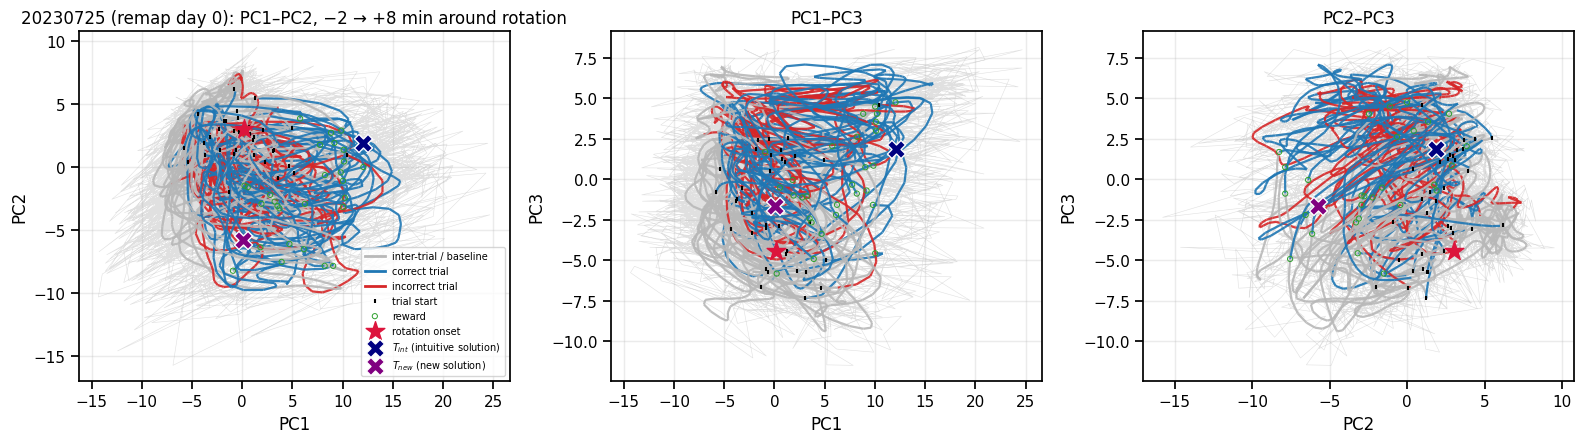

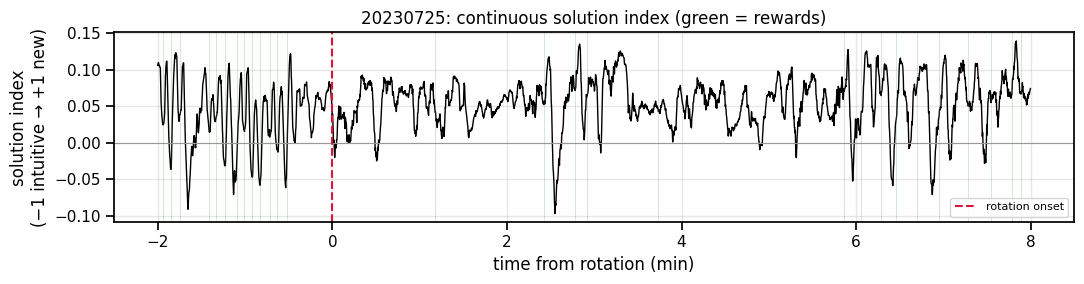

In [6]:
day0 = REMAP_DAYS[0]
W0 = trajectory_window(day0, beh.iloc[0].remap_min - 2, beh.iloc[0].remap_min + 8)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
draw_trajectory(W0, (0, 1), axes[0], title=f"{day0} (remap day 0): PC1–PC2, −2 → +8 min around rotation")
draw_trajectory(W0, (0, 2), axes[1], title="PC1–PC3", legend=False)
draw_trajectory(W0, (1, 2), axes[2], title="PC2–PC3", legend=False)
fig.tight_layout(); fig.savefig(OUT / "A3_traj_day0.png", dpi=150); plt.show()

# continuous solution index over the same window
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(W0["tmin"], pd.Series(W0["sol"]).rolling(int(3 * SRB), min_periods=1, center=True).mean(), lw=1, color="k")
ax.axhline(0, color="0.6", lw=0.8); ax.axvline(0, color="crimson", ls="--", label="rotation onset")
for f in W0["ev"]["rewards"]: ax.axvline(W0["tmin"][f], color="tab:green", alpha=0.25, lw=0.6)
ax.set(xlabel="time from rotation (min)", ylabel="solution index\n(−1 intuitive → +1 new)",
       title=f"{day0}: continuous solution index (green = rewards)"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(OUT / "A3_solindex_day0.png", dpi=150); plt.show()

### 3b · A later day — the same window, for contrast

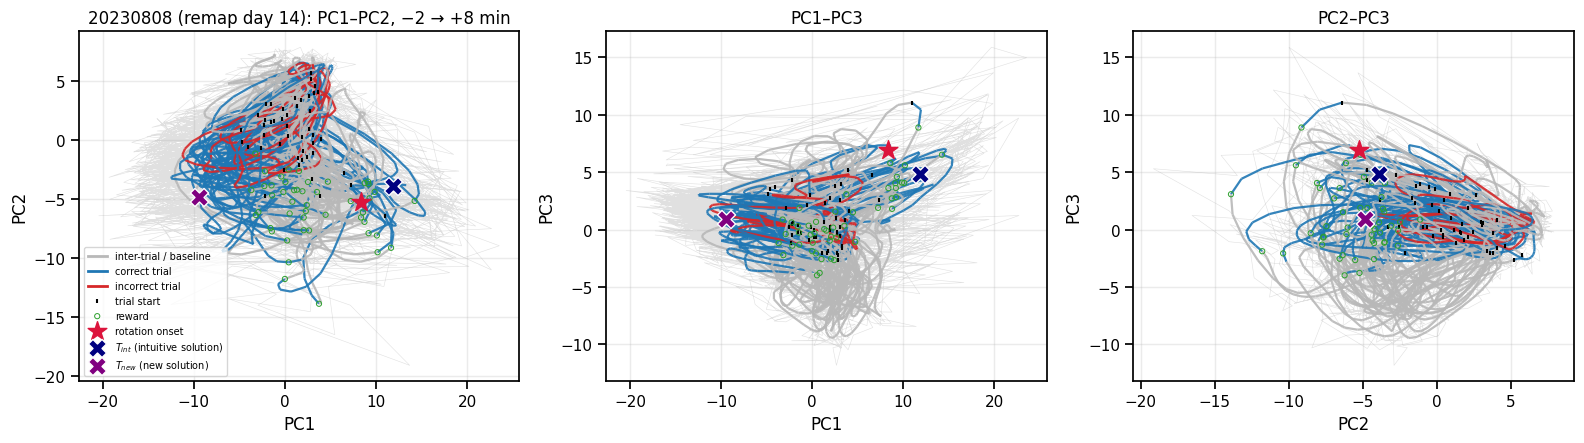

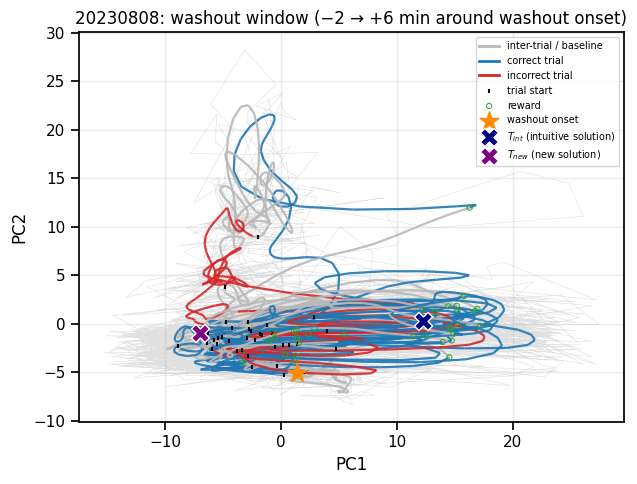

In [7]:
dayL = REMAP_DAYS[-1]; bl = beh[beh.day == dayL].iloc[0]
WL = trajectory_window(dayL, bl.remap_min - 2, bl.remap_min + 8)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
draw_trajectory(WL, (0, 1), axes[0], title=f"{dayL} (remap day {int(bl.remap_day)}): PC1–PC2, −2 → +8 min")
draw_trajectory(WL, (0, 2), axes[1], title="PC1–PC3", legend=False)
draw_trajectory(WL, (1, 2), axes[2], title="PC2–PC3", legend=False)
fig.tight_layout(); fig.savefig(OUT / "A3_traj_late.png", dpi=150); plt.show()

# washout window on the same later day
WW = trajectory_window(dayL, bl.wash_min - 2, bl.wash_min + 6)
fig, ax = plt.subplots(figsize=(6.5, 5))
draw_trajectory(WW, (0, 1), ax, title=f"{dayL}: washout window (−2 → +6 min around washout onset)")
fig.tight_layout(); fig.savefig(OUT / "A3_traj_late_washout.png", dpi=150); plt.show()

## 4 · Animation of the trajectory through the rotation  *(core visualisation)*

Written to **MP4** so it can be scrubbed, paused and stepped back and forth in any video player.

**Layout** (figure ≈ 6 × 4 units): the top row is three square PC-pair panels — **PC1–PC2**, **PC2–PC3**,
**PC1–PC3** — sharing one PCA space; the bottom row spans the full width with the **cursor plot**: the
logged BCI cursor over time (black) with the solution index on a second axis (purple), reward events,
rotation/washout lines and a moving time marker.

Every feature from the static figure is retained: a fading **trail** of recent activity, a
**current-state cursor** coloured by behavioural state (correct / incorrect / inter-trial), accumulating
reward markers, the `T_int` / `T_new` templates, rotation and washout stars, and a dynamic title
showing time-from-rotation, block and behavioural state.

Playback is **4× slower** than the first version (same fps, one quarter of the data-time per frame),
so the search is easy to follow. The drawn path is additionally **smoothed for display only**
(`TRAJ_SMOOTH_SIGMA_BINS`: a Gaussian over time applied to the *projected* path, ~330 ms by default),
with the **raw 6 Hz path always shown faintly underneath**. Smoothing here is a weighted average of
neighbouring real states, so the curve never visits anywhere the population did not go; it does damp
fast excursions, which is exactly why **no quantitative result in this notebook uses it** — speed,
path length, `p`/`resid` and every statistic are computed on the unsmoothed data. Set it to `0` to
draw the raw path. `RENDER_FULL_ANIMATIONS` is off by default — the cell below runs a
short **smoke test** to prove the pipeline works; flip the flag for the full movies.

In [8]:
import imageio_ffmpeg
plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
print("ffmpeg:", animation.writers.is_available("ffmpeg"))

PC_PAIRS = [(0, 1), (1, 2), (0, 2)]     # PC1-PC2, PC2-PC3, PC1-PC3
def make_trajectory_animation(day, t0_min, t1_min, out_path, *, step_sec=0.75, trail_sec=25.0,
                              fps=20, dpi=110, k=6, figsize=(20, 10), pairs=PC_PAIRS,
                              smooth_sigma=TRAJ_SMOOTH_SIGMA_BINS, ts_window_min=2):
    '''Animate the trajectory in ONE PCA space: 3 PC-pair panels + a full-width cursor panel. -> MP4.

    The bottom panel scrolls with the video: it always shows a `ts_window_min`-minute span centred
    on the current time, with the time marker pinned at the centre of the axis.'''
    W = trajectory_window(day, t0_min, t1_min, k=k)
    P_raw, lab, sol, tmin, ev = W["P"], W["lab"], W["sol"], W["tmin"], W["ev"]
    P = smooth_path(P_raw, smooth_sigma)          # display only; event timing is untouched
    step = max(int(round(step_sec * SRB)), 1); trail = max(int(round(trail_sec * SRB)), 2)
    frames = list(range(trail, len(P), step))
    sol_s = pd.Series(sol).rolling(int(3 * SRB), min_periods=1, center=True).mean().to_numpy()

    # logged BCI cursor for this window, averaged into the same bins
    cur_raw = na.load_cursor(r, day)
    b = BIN_SIZE_FRAMES; nb = len(cur_raw) // b
    cur_binned = cur_raw[:nb * b].reshape(nb, b).mean(1)
    cur = cur_binned[W["w0"]:W["w1"]]
    if len(cur) < len(tmin):                      # pad if the WS trace is shorter
        cur = np.concatenate([cur, np.full(len(tmin) - len(cur), np.nan)])

    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(2, 4, height_ratios=[1, 1], hspace=0.28, wspace=0.24)
    #axP = [fig.add_subplot(gs[0, c]) for c in range(3)]
    #axC = fig.add_subplot(gs[1, :])
    axP = [fig.add_subplot(gs[:, 0:2]), fig.add_subplot(gs[1, 2]), fig.add_subplot(gs[1, 3])]
    axC = fig.add_subplot(gs[0, 2:4])

    trails, cursors, rews = [], [], []
    for ax, (a, bb) in zip(axP, pairs):
        pts = P[:, [a, bb]]
        #ax.plot(P_raw[:, a], P_raw[:, bb], color="0.90", lw=0.3, alpha=0.8, zorder=0)  # raw 6 Hz path
        #ax.plot(pts[:, 0], pts[:, 1], color="0.72", lw=0.5, zorder=1)                  # smoothed, faint
        if W["tpl_proj"] is not None:
            ti, tn = W["tpl_proj"]
            ax.scatter(ti[a], ti[bb], s=150, marker="X", color="navy", edgecolor="w", zorder=7, label="$T_{int}$")
            ax.scatter(tn[a], tn[bb], s=150, marker="X", color="purple", edgecolor="w", zorder=7, label="$T_{new}$")
        #if ev["remap"] is not None:
        #    ax.scatter(*pts[ev["remap"]], s=210, marker="*", color="crimson", zorder=6, label="rotation")
        #if ev["wash"] is not None:
        #    ax.scatter(*pts[ev["wash"]], s=210, marker="*", color="darkorange", zorder=6, label="washout")
        ax.set_xlim(*np.percentile(P_raw[:, a], [0.2, 99.8])); ax.set_ylim(*np.percentile(P_raw[:, bb], [0.2, 99.8]))
        ax.set(xlabel=f"PC{a+1}", ylabel=f"PC{bb+1}"); ax.set_aspect("auto"); ax.grid(alpha=0.25)
        lc = LineCollection([], linewidths=1.7); ax.add_collection(lc); trails.append(lc)
        cursors.append(ax.scatter([], [], s=110, zorder=9, edgecolor="k", linewidth=0.7))
        rews.append(ax.scatter([], [], s=10, facecolor="none", edgecolor="tab:green", lw=0.9, zorder=8))
    axP[0].legend(fontsize=15, loc="upper right")

    # ---- bottom row: cursor plot ----
    axC.plot(tmin, cur, color="0.35", lw=0.8, label="BCI cursor (logged)")
    axC.set(xlabel="time from rotation (min)", ylabel="BCI cursor")
    axC.grid(alpha=0.3)
    ts_half = ts_window_min / 2.0                      # bottom panel shows now +/- ts_half minutes
    axC.set_xlim(tmin[frames[0]] - ts_half, tmin[frames[0]] + ts_half)
    if ev["rewards"]:
        axC.scatter(tmin[ev["rewards"]], cur[ev["rewards"]], s=16, facecolor="none",
                    edgecolor="tab:green", lw=0.8, label="reward", zorder=4)
    for f, cc, lb in [(ev["remap"], "crimson", "rotation"), (ev["wash"], "darkorange", "washout")]:
        if f is not None: 
            axC.axvline(tmin[f], color=cc, ls="--", lw=1.4, label=lb)

    axS = axC.twinx()
    axS.plot(tmin, sol_s, color="purple", lw=0.9, alpha=0.55)
    axS.set_ylabel("solution index (-1 int -> +1 new)", color="purple")
    axS.tick_params(axis="y", colors="purple")
    live, = axC.plot([], [], color="k", lw=1.6, zorder=5)
    vline = axC.axvline(tmin[0], color="k", lw=1.5, zorder=6)
    axC.legend(fontsize=8, loc="upper left", ncol=4)
    ttl = fig.suptitle("", fontsize=13)

    def update(i):
        s0 = max(i - trail, 0)
        st = int(lab[i]); col = STATE_COLORS.get(st, "0.7")
        rs = [f for f in ev["rewards"] if f <= i]
        for lc, sc, rsc, (a, bb) in zip(trails, cursors, rews, pairs):
            pts = P[:, [a, bb]]; seg_pts = pts[s0:i + 1]
            segs = np.stack([seg_pts[:-1], seg_pts[1:]], axis=1) if len(seg_pts) > 1 else np.empty((0, 2, 2))
            lc.set_segments(segs); lc.set_color([STATE_COLORS.get(int(x), "0.7") for x in lab[s0:i]])
            sc.set_offsets(pts[i][None, :]); sc.set_color(col)
            rsc.set_offsets(pts[rs] if rs else np.empty((0, 2)))
        live.set_data(tmin[:i + 1], cur[:i + 1]); vline.set_xdata([tmin[i], tmin[i]])
        axC.set_xlim(tmin[i] - ts_half, tmin[i] + ts_half)   # scroll; axS shares this x-axis
        phase = ("INTUITIVE" if (ev["remap"] is None or i < ev["remap"])
                 else ("NEW AXIS" if (ev["wash"] is None or i < ev["wash"]) else "WASHOUT"))
        ttl.set_text(f"{day}   t = {tmin[i]:+.2f} min from rotation   |   block: {phase}   |   {STATE_LABEL.get(st,'')}")
        return (*trails, *cursors, *rews, live, vline, ttl)

    anim = animation.FuncAnimation(fig, update, frames=frames, blit=False)
    anim.save(str(out_path), writer=animation.FFMpegWriter(fps=fps, bitrate=2400), dpi=dpi)
    plt.close(fig)
    return out_path, len(frames)

RENDER_FULL_ANIMATIONS = False   # <- set True to render the full movies (slow)

# --- smoke test: 45 s of data, a handful of frames, low dpi ---
smoke, nfr = make_trajectory_animation(REMAP_DAYS[0], beh.iloc[0].remap_min - 0.4, beh.iloc[0].remap_min + 0.35,
                                       OUT / "smoke_test.mp4", step_sec=1.5, trail_sec=15.0, fps=8,
                                       dpi=70, figsize=(9, 6))
print(f"smoke test OK -> {smoke.name} ({nfr} frames, {smoke.stat().st_size/1e6:.2f} MB)")

ffmpeg: True
smoke test OK -> smoke_test.mp4 (20 frames, 0.16 MB)


In [ ]:
b0 = beh.iloc[0]
# first remapping day: 2 min before the rotation through the end of washout
p_, n_ = make_trajectory_animation(REMAP_DAYS[0], b0.remap_min - 1, b0.remap_min + 1,
                                    OUT / "anim_day0_full.mp4", smooth_sigma =2, step_sec=1, fps=20)
print("day 0 full:", p_.name, n_, "frames")

day 0 full: anim_day0_full.mp4 95 frames


In [9]:
RENDER_FULL_ANIMATIONS_FULL = True
if RENDER_FULL_ANIMATIONS_FULL:
    for ii in [0, 3, 6, 9, 12]:
        b = beh.iloc[ii]
        day = b.day
        p_, n_ = make_trajectory_animation(day, b.remap_min - 5, b.remap_min + 10,
                                        OUT / f"anim_day{ii}_full.mp4", smooth_sigma=2, step_sec=.25, fps=20)
        print(f"day {ii} full:", p_.name, n_, "frames")

day 0 full: anim_day0_full.mp4 2625 frames
day 3 full: anim_day3_full.mp4 2625 frames
day 6 full: anim_day6_full.mp4 2625 frames
day 9 full: anim_day9_full.mp4 2625 frames
day 12 full: anim_day12_full.mp4 2625 frames


KeyboardInterrupt: 

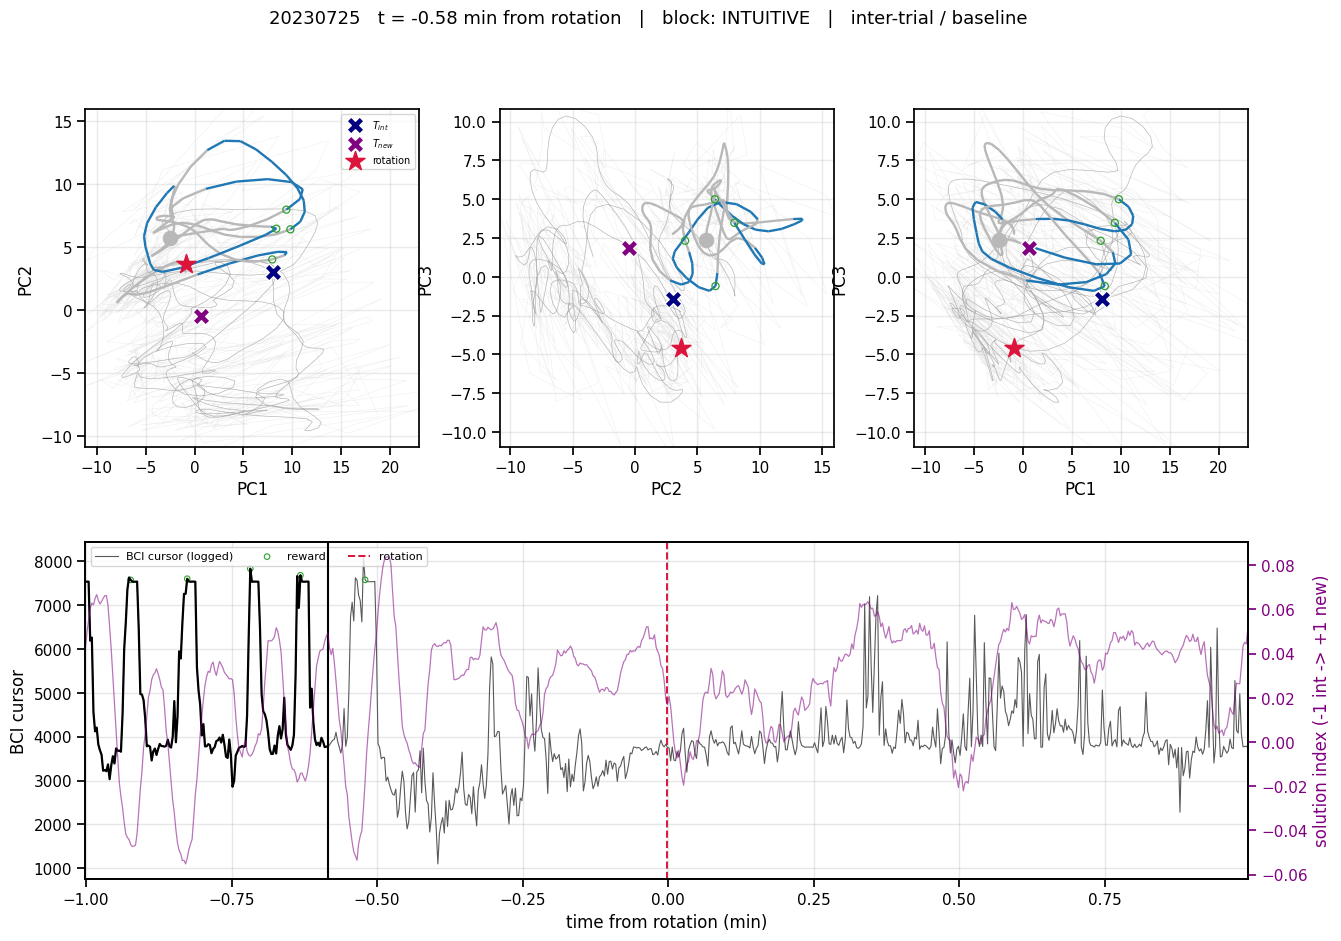

In [ ]:
RENDER_FULL_ANIMATIONS = False
   # <- set True to render the full movies (slow)
if RENDER_FULL_ANIMATIONS:
    b0 = beh.iloc[0]
    # first remapping day: 2 min before the rotation through the end of washout
    p_, n_ = make_trajectory_animation(REMAP_DAYS[0], b0.remap_min - 1, b0.remap_min + 1,
                                       OUT / "anim_day0_full.mp4", step_sec=1.0, fps=20)
    print("day 0 full:", p_.name, n_, "frames")
    bl = beh[beh.day == REMAP_DAYS[-1]].iloc[0]
    for tag, (t0, t1) in {"rotation": (bl.remap_min - 2, bl.remap_min + 6),
                          "washout":  (bl.wash_min - 2,  bl.wash_min + 6)}.items():
        p_, n_ = make_trajectory_animation(REMAP_DAYS[-1], t0, t1, OUT / f"anim_lateday_{tag}.mp4",
                                           step_sec=0.5, fps=20)
        print(f"late day {tag}:", p_.name, n_, "frames")
else:
    print("RENDER_FULL_ANIMATIONS = False - only the smoke test ran. Set it True for the full movies:")
    print("  day 0   : rotation-2min -> washout+6min  (step_sec=1.0, ~4000 frames)")
    print("  late day: +/-rotation and +/-washout      (step_sec=0.5)")
    print("Playback speed is set by step_sec (data-seconds per frame) / fps; lower step_sec = slower.")

## 5 · Solution-space geometry: where is the population relative to the two solutions?

A single scalar cannot answer this, so each state is described by **two** numbers relative to the line
joining the templates:

* **`p`** — position along that line: `p = ((x − T_int)·u)/L` with `u = (T_new − T_int)/L`.
  **`p ≈ 0` = intuitive solution, `p ≈ 1` = new solution.**
* **`resid`** — perpendicular distance from the line, in units of the *within-day trial spread*
  (mean distance of intuitive-block endpoints from `T_int`). **Large `resid` = far from both
  solutions**, i.e. off the axis connecting them.

`p` is well conditioned: intuitive and new endpoint states separate with d′ ≈ 4.3–5.9. Two independent
checks validate it (neither is built in): washout endpoints should fall back to `p ≈ 0`, and the
inter-trial state — which is not a solution at all — should sit off the line with a large
`resid`.

In [7]:
def solution_coords(states, T_int, T_new, spread):
    '''p along T_int->T_new (0=intuitive, 1=new) and perpendicular residual in trial-spread units.'''
    if len(states) == 0: return np.array([]), np.array([])
    diff = T_new - T_int; L = np.linalg.norm(diff); u = diff / L
    d = states - T_int; p = (d @ u) / L
    resid = np.linalg.norm(d - np.outer(p * L, u), axis=1) / spread
    return p, resid

def day_geometry(day, di):
    X, trials, rew, blocks, T = load_day(day)
    tpl = solution_templates(X, trials, blocks)
    if tpl is None: return []
    T_int, T_new, L = tpl
    b_int, b_new, b_wash = blocks
    # within-day noise scale: typical distance of intuitive endpoints from their own template
    spread = float(np.mean(np.linalg.norm(endpoint_states(X, trials, block_trials(trials, b_int, 1)) - T_int, axis=1)))
    rows = []
    for bname, b in [("intuitive", b_int), ("new", b_new), ("washout", b_wash)]:
        idx = ok_trials(trials, list(range(b.first_trial, b.last_trial + 1)))
        p, res = solution_coords(endpoint_states(X, trials, idx), T_int, T_new, spread)
        for k, i in enumerate(idx):
            rows.append(dict(day=day, remap_day=di, block=bname, k=k, success=trials.success[i],
                             p=p[k], resid=res[k], L=L, spread=spread))
    base_iv = na.baseline_intervals(trials, T, exclude_sec=10.0, sr=SRB, min_len_sec=2.0,
                                    reward_frames=rew, miss_dur_sec=MISS_WINDOW_SEC)
    p, res = solution_coords(na.subsample_rows(na.intervals_to_matrix(X, base_iv), 1500), T_int, T_new, spread)
    rows.append(dict(day=day, remap_day=di, block="baseline", k=-1, success=np.nan,
                     p=float(np.mean(p)), resid=float(np.mean(res)), L=L, spread=spread))
    return rows

geo_fp2 = OUT / f"solution_coords_{TAG}.csv"
if USE_CACHE and geo_fp2.exists():
    sol_df = pd.read_csv(geo_fp2); sol_df["day"] = sol_df["day"].astype(str)
else:
    rows = []
    for i, d in enumerate(tqdm(REMAP_DAYS, desc="solution coords")): rows += day_geometry(d, i)
    sol_df = pd.DataFrame(rows); sol_df.to_csv(geo_fp2, index=False)

chk = sol_df[sol_df.success == 1].groupby("block")[["p", "resid"]].mean()
chk.loc["baseline"] = sol_df[sol_df.block == "baseline"][["p", "resid"]].mean()
print("VALIDATION (mean over days):"); print(chk.round(2).to_string())
print(""); print("-> washout successes fall back to p~0 (independent check that p tracks the SOLUTION, not time),")
print("   and the ITI state sits at intermediate p with the LARGEST residual = near NEITHER solution.")

solution coords:   0%|          | 0/15 [00:00<?, ?it/s]

VALIDATION (mean over days):
              p  resid
block                 
intuitive -0.00   0.99
new        0.96   0.83
washout    0.06   1.20
baseline   0.61   1.23

-> washout successes fall back to p~0 (independent check that p tracks the SOLUTION, not time),
   and the ITI state sits at intermediate p with the LARGEST residual = near NEITHER solution.


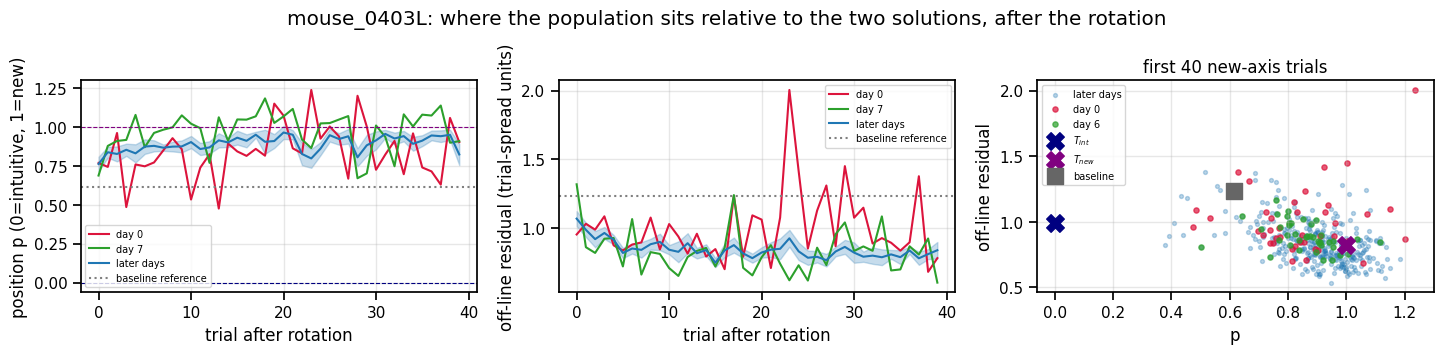

day 0  first 5 trials after rotation: p=+0.74  resid=0.99
day 6  first 5 trials after rotation: p=+0.89  resid=0.97
later  first 5 trials after rotation: p=+0.82  resid=0.97
p, first 5 trials, day0 vs later: MWU p=0.2809   (baseline reference p=0.61, resid=1.23)
off-line residual over first 40 trials: day0=1.00 later=0.85 MWU p=8.50e-06


In [13]:
new_tr = sol_df[(sol_df.block == "new") & (sol_df.k < 40)]
iti_p = sol_df[sol_df.block == "baseline"].p.mean(); iti_r = sol_df[sol_df.block == "baseline"].resid.mean()
fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.6))
for ax, col, lab, ref in [(axes[0], "p", "position p (0=intuitive, 1=new)", iti_p),
                          (axes[1], "resid", "off-line residual (trial-spread units)", iti_r)]:
    for lbl, sel, cc in [("day 0", new_tr[new_tr.remap_day == 0], "crimson"),
                         ("day 7", new_tr[new_tr.remap_day == 7], "tab:green"),
                         ("later days", new_tr[new_tr.remap_day > 5], "tab:blue")]:
        g = sel.groupby("k")[col].agg(["mean", "sem"])
        ax.plot(g.index, g["mean"], color=cc, label=lbl)
        ax.fill_between(g.index, g["mean"] - g["sem"], g["mean"] + g["sem"], color=cc, alpha=0.25)
    ax.axhline(ref, color="0.5", ls=":", label="baseline reference")
    if col == "p":
        ax.axhline(0, color="navy", lw=0.8, ls="--"); ax.axhline(1, color="purple", lw=0.8, ls="--")
    ax.set(xlabel="trial after rotation", ylabel=lab); ax.legend(fontsize=7); ax.grid(alpha=0.3)
g0 = new_tr[new_tr.remap_day == 0]; g7=new_tr[new_tr.remap_day == 7]; gL = new_tr[new_tr.remap_day > 5]
axes[2].scatter(gL.p, gL.resid, s=8, alpha=0.3, color="tab:blue", label="later days")
axes[2].scatter(g0.p, g0.resid, s=14, alpha=0.7, color="crimson", label="day 0")
axes[2].scatter(g6.p, g6.resid, s=14, alpha=0.7, color="tab:green", label="day 6")
axes[2].scatter([0], [sol_df[(sol_df.block=="intuitive")&(sol_df.success==1)].resid.mean()], s=160, marker="X", color="navy", zorder=5, label="$T_{int}$")
axes[2].scatter([1], [sol_df[(sol_df.block=="new")&(sol_df.success==1)].resid.mean()], s=160, marker="X", color="purple", zorder=5, label="$T_{new}$")
axes[2].scatter([iti_p], [iti_r], s=140, marker="s", color="0.4", zorder=5, label="baseline")
axes[2].set(xlabel="p", ylabel="off-line residual", title="first 40 new-axis trials"); axes[2].legend(fontsize=7); axes[2].grid(alpha=0.3)
fig.suptitle(f"{MOUSE}: where the population sits relative to the two solutions, after the rotation")
fig.tight_layout(); fig.savefig(OUT / "A5_solution_coords.png", dpi=150); plt.show()

for lbl, sel in [("day 0", g0), ("day 6", g7), ("later", gL)]:
    f5 = sel[sel.k < 5]
    print(f"{lbl:6s} first 5 trials after rotation: p={f5.p.mean():+.2f}  resid={f5.resid.mean():.2f}")
u, pv = mannwhitneyu(g0[g0.k < 5].p, gL[gL.k < 5].p)
print(f"p, first 5 trials, day0 vs later: MWU p={pv:.4f}   (baseline reference p={iti_p:.2f}, resid={iti_r:.2f})")
u2, pv2 = mannwhitneyu(g0.resid, gL.resid)
print(f"off-line residual over first 40 trials: day0={g0.resid.mean():.2f} later={gL.resid.mean():.2f} MWU p={pv2:.2e}")

## 6 · Exploration geometry aligned to the rotation

Independently of the templates: if the animal *searches*, activity right after the rotation should
move **faster**, cover **more** state space, and become **higher-dimensional**. In a common per-day
PCA (`K_GEOM` dims, fitted −5 → +15 min around the rotation) we compute, in 30 s sliding windows,
path **speed**, **radius of gyration**, and **participation ratio**, each z-scored to that day's own
pre-rotation baseline so days are comparable.

In [ ]:
def geometry_rows(day, di):
    X, trials, rew, blocks, T = load_day(day)
    b_new = blocks[1]; rb = b_new.start_frame
    w0, w1 = int(max(rb - 5 * 60 * SRB, 0)), int(min(rb + 15 * 60 * SRB, T))
    sub = na.fit_subspace(X[:, w0:w1].T, K_GEOM); P = sub.project(X[:, w0:w1].T)
    win, step = int(WIN_SEC * SRB), int(STEP_SEC * SRB)
    return [dict(day=day, remap_day=di, t_min=((w0 + s + win / 2) - rb) / SRB / 60,
                 speed=na.path_speed(P[s:s + win]), rgyr=na.radius_of_gyration(P[s:s + win]),
                 pr=na.pca_spectrum(P[s:s + win]).participation_ratio)
            for s in range(0, P.shape[0] - win, step)]

geo_fp = OUT / f"geometry_{TAG}.csv"
if USE_CACHE and geo_fp.exists():
    geo = pd.read_csv(geo_fp); geo["day"] = geo["day"].astype(str)
else:
    rows = []
    for i, d in enumerate(tqdm(REMAP_DAYS, desc="geometry")): rows += geometry_rows(d, i)
    geo = pd.DataFrame(rows); geo.to_csv(geo_fp, index=False)

geo = geo.sort_values(["remap_day", "t_min"]).reset_index(drop=True)
pre = geo[geo.t_min < 0]
for c in ["speed", "rgyr", "pr"]:
    mu = geo.remap_day.map(pre.groupby("remap_day")[c].mean())
    sd = geo.remap_day.map(pre.groupby("remap_day")[c].std())
    geo[f"z_{c}"] = (geo[c] - mu) / (sd + 1e-9)

bins = np.arange(-5, 15.01, 0.5); geo["tb"] = pd.cut(geo.t_min, bins, labels=(bins[:-1] + 0.25))
fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.4))
for ax, col, lab in zip(axes, ["z_speed", "z_rgyr", "z_pr"], ["speed", "radius of gyration", "participation ratio"]):
    for lbl, sel, cc in [("day 0", geo[geo.remap_day == 0], "crimson"), ("later days", geo[geo.remap_day > 0], "tab:blue")]:
        g = sel.groupby("tb", observed=True)[col].agg(["mean", "sem"]).reset_index(); x = g.tb.astype(float)
        ax.plot(x, g["mean"], color=cc, label=lbl); ax.fill_between(x, g["mean"] - g["sem"], g["mean"] + g["sem"], color=cc, alpha=0.25)
    ax.axvline(0, color="crimson", ls="--", lw=1); ax.axhline(0, color="0.6", lw=0.8)
    ax.set(xlabel="time from rotation (min)", ylabel=f"{lab} (z vs pre-rotation)", title=lab); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.suptitle(f"{MOUSE}: exploration geometry around the rotation")
fig.tight_layout(); fig.savefig(OUT / "A6_exploration_geometry.png", dpi=150); plt.show()

post = geo[(geo.t_min > 0) & (geo.t_min < 5)]
for col in ["z_speed", "z_rgyr", "z_pr"]:
    a = post[post.remap_day == 0][col].dropna(); b_ = post[post.remap_day > 0][col].dropna()
    u, pv = mannwhitneyu(a, b_)
    print(f"0-5 min after rotation, {col:8s}: day0={a.mean():+.2f}  later={b_.mean():+.2f}  MWU p={pv:.4f}")
print(""); print("READ: activity speeds up after the rotation on BOTH day 0 and later days, and day 0 speeds up more.")
print("But spread (radius of gyration) does NOT increase (it falls on all days), and local dimensionality")
print("rises LESS on day 0 than on later days. So the post-rotation change is a faster, more driven")
print("trajectory rather than a large-volume, high-dimensional random search.")

geometry:   0%|          | 0/15 [00:00<?, ?it/s]

## 7 · Does the animal perseverate on the old solution? (first remapping day)

A natural hypothesis is that after the uncued rotation the animal first keeps producing the **old**
solution (`p ≈ 0`) and only then explores. We test it directly on day 0: the ordered trial-by-trial
`p`, off-line residual, and — as the behavioural counterpart — the within-trial **maximum cursor
value**, which says how close each failed attempt came to the reward threshold.

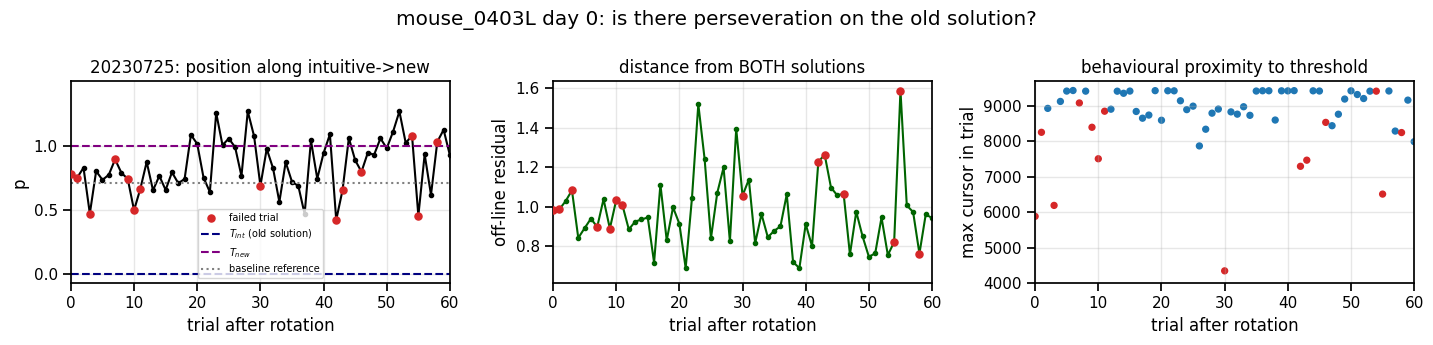

first 3 trials after the rotation: p = [0.78 0.75 0.83]   (p~0 would mean perseveration on the OLD solution)
day-0 baseline reference p = 0.71
failed trials, first 20 trials (n=7): p=+0.68 resid=0.98
failed trials, later          (n=40):  p=+0.74 resid=1.01
successful trials on day 0: p=+0.96; failures: p=+0.73

READ: there is NO endpoint-level perseveration -- from the very first post-rotation trial the
population has already left the old solution (p well above 0, near the baseline level). What separates
failures from successes is not a return to the old solution but falling short of T_new.


In [ ]:
day0 = REMAP_DAYS[0]
X, trials, rew, blocks, T = load_day(day0)
T_int, T_new, L = solution_templates(X, trials, blocks)
b_int, b_new, b_wash = blocks
spread = float(np.mean(np.linalg.norm(endpoint_states(X, trials, block_trials(trials, b_int, 1)) - T_int, axis=1)))
new_idx = ok_trials(trials, list(range(b_new.first_trial, b_new.last_trial + 1)))
p0, r0 = solution_coords(endpoint_states(X, trials, new_idx), T_int, T_new, spread)
succ = np.array([trials.success[i] for i in new_idx])
cursor = na.load_cursor(r, day0)
maxc = np.array([np.nanmax(cursor[int(trials.start[i] * BIN_SIZE_FRAMES):
                                  min(int(trials.end[i] * BIN_SIZE_FRAMES), len(cursor))]) for i in new_idx])
iti_p0 = sol_df[(sol_df.block == "baseline") & (sol_df.remap_day == 0)].p.mean()

kk = np.arange(len(new_idx))
fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.5))
axes[0].plot(kk, p0, "-o", ms=3, color="k")
axes[0].scatter(kk[succ == 0], p0[succ == 0], s=26, color="tab:red", zorder=3, label="failed trial")
axes[0].axhline(0, color="navy", ls="--", label="$T_{int}$ (old solution)")
axes[0].axhline(1, color="purple", ls="--", label="$T_{new}$")
axes[0].axhline(iti_p0, color="0.5", ls=":", label="baseline reference")
axes[0].set(xlim=(0, 60), xlabel="trial after rotation", ylabel="p", title=f"{day0}: position along intuitive->new")
axes[0].legend(fontsize=7)
axes[1].plot(kk, r0, "-o", ms=3, color="darkgreen")
axes[1].scatter(kk[succ == 0], r0[succ == 0], s=26, color="tab:red", zorder=3)
axes[1].set(xlim=(0, 60), xlabel="trial after rotation", ylabel="off-line residual", title="distance from BOTH solutions")
axes[2].scatter(kk, maxc, s=18, c=np.where(succ == 1, "tab:blue", "tab:red"))
axes[2].set(xlim=(0, 60), xlabel="trial after rotation", ylabel="max cursor in trial", title="behavioural proximity to threshold")
for a in axes: a.grid(alpha=0.3)
fig.suptitle(f"{MOUSE} day 0: is there perseveration on the old solution?")
fig.tight_layout(); fig.savefig(OUT / "A7_day0.png", dpi=150); plt.show()

print(f"first 3 trials after the rotation: p = {np.round(p0[:3], 2)}   (p~0 would mean perseveration on the OLD solution)")
print(f"day-0 baseline reference p = {iti_p0:.2f}")
fails = np.where(succ == 0)[0]; early, late = fails[fails < 20], fails[fails >= 20]
if len(early) and len(late):
    print(f"failed trials, first 20 trials (n={len(early)}): p={p0[early].mean():+.2f} resid={r0[early].mean():.2f}")
    print(f"failed trials, later          (n={len(late)}):  p={p0[late].mean():+.2f} resid={r0[late].mean():.2f}")
print(f"successful trials on day 0: p={p0[succ==1].mean():+.2f}; failures: p={p0[succ==0].mean():+.2f}")
print(""); print("READ: there is NO endpoint-level perseveration -- from the very first post-rotation trial the")
print("population has already left the old solution (p well above 0, near the baseline level). What separates")
print("failures from successes is not a return to the old solution but falling short of T_new.")

## 8 · Within-trial dynamics: last pre-rotation vs first post-rotation trials

From day 1 on the animal is usually correct on the **first** new-axis trial, so any "detection" of the
change must happen inside a trial. Aligning to trial start, we follow `p` through the trial for the
**last pre-rotation trials** and the **first post-rotation trials**, pooled over later days.

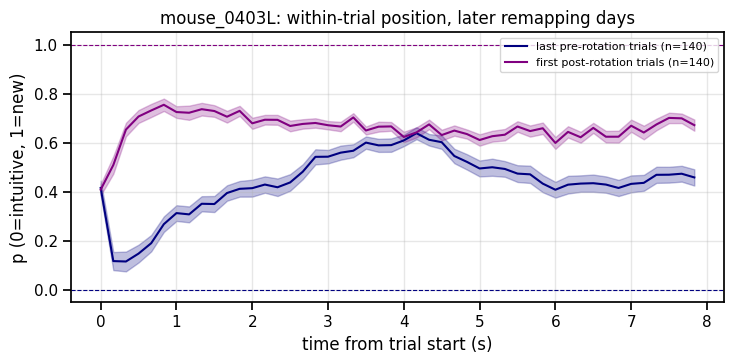

at trial onset:  pre=+0.42  post=+0.41   (same self-initiated starting state)
pre-rotation trials dive to p=+0.12 at 0.33 s  (commit to the INTUITIVE solution)
post-rotation trials rise to p=+0.75 at 0.83 s (commit to the NEW solution)
first sustained separation (>2 SEM for 3 bins): 0.17 s after trial start

READ: both trial types begin from the SAME self-initiated state (p~0.42), then within a
quarter second commit in OPPOSITE directions -- pre-rotation toward T_int, post-rotation toward
T_new. On later days the switch is therefore essentially immediate at trial onset, not a gradual
within-trial search, and no failed trial is needed to trigger it.
Caveat: the fixed 8 s window extends past short trials, pulling both curves toward baseline late on.


In [ ]:
def within_trial_p(day, n_pre=10, n_post=10, dur_sec=8.0):
    X, trials, rew, blocks, T = load_day(day)
    tpl = solution_templates(X, trials, blocks)
    if tpl is None: return None
    T_int, T_new, L = tpl
    b_int, b_new, _ = blocks
    spread = float(np.mean(np.linalg.norm(endpoint_states(X, trials, block_trials(trials, b_int, 1)) - T_int, axis=1)))
    nb = int(dur_sec * SRB)
    def curves(idxs):
        out = []
        for i in idxs:
            s = int(round(trials.start[i])); e = min(s + nb, X.shape[1])
            if e - s < nb: continue
            p, _ = solution_coords(X[:, s:e].T, T_int, T_new, spread); out.append(p)
        return np.array(out) if out else np.empty((0, nb))
    pre = curves(ok_trials(trials, list(range(b_int.last_trial - n_pre + 1, b_int.last_trial + 1))))
    post = curves(ok_trials(trials, list(range(b_new.first_trial, b_new.first_trial + n_post))))
    return pre, post

wt_fp = OUT / f"within_trial_{TAG}.npz"
if USE_CACHE and wt_fp.exists():
    _z = np.load(wt_fp); pre_all, post_all = _z["pre"], _z["post"]
else:
    P_, Q_ = [], []
    for d in tqdm(REMAP_DAYS[1:], desc="within-trial"):
        res = within_trial_p(d)
        if res is None: continue
        if len(res[0]): P_.append(res[0])
        if len(res[1]): Q_.append(res[1])
    pre_all, post_all = np.concatenate(P_, 0), np.concatenate(Q_, 0)
    np.savez(wt_fp, pre=pre_all, post=post_all)
tt = np.arange(pre_all.shape[1]) / SRB

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for arr, cc, lbl in [(pre_all, "navy", f"last pre-rotation trials (n={len(pre_all)})"),
                     (post_all, "purple", f"first post-rotation trials (n={len(post_all)})")]:
    m, se = arr.mean(0), arr.std(0) / np.sqrt(len(arr))
    ax.plot(tt, m, color=cc, label=lbl); ax.fill_between(tt, m - se, m + se, color=cc, alpha=0.25)
ax.axhline(0, color="navy", ls="--", lw=0.8); ax.axhline(1, color="purple", ls="--", lw=0.8)
ax.set(xlabel="time from trial start (s)", ylabel="p (0=intuitive, 1=new)",
       title=f"{MOUSE}: within-trial position, later remapping days"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(OUT / "A8_within_trial.png", dpi=150); plt.show()

m1, m2 = pre_all.mean(0), post_all.mean(0)
se = np.sqrt(pre_all.var(0) / len(pre_all) + post_all.var(0) / len(post_all))
sep = (m2 - m1) > 2 * se
lat = next((tt[i] for i in range(len(sep) - 2) if sep[i:i + 3].all()), np.nan)
w3 = int(3 * SRB)
i_pre, i_post = int(np.argmin(m1[:w3])), int(np.argmax(m2[:w3]))
print(f"at trial onset:  pre={m1[0]:+.2f}  post={m2[0]:+.2f}   (same self-initiated starting state)")
print(f"pre-rotation trials dive to p={m1[i_pre]:+.2f} at {tt[i_pre]:.2f} s  (commit to the INTUITIVE solution)")
print(f"post-rotation trials rise to p={m2[i_post]:+.2f} at {tt[i_post]:.2f} s (commit to the NEW solution)")
print(f"first sustained separation (>2 SEM for 3 bins): {lat if np.isfinite(lat) else float('nan'):.2f} s after trial start")
print(""); print("READ: both trial types begin from the SAME self-initiated state (p~0.42), then within a")
print("quarter second commit in OPPOSITE directions -- pre-rotation toward T_int, post-rotation toward")
print("T_new. On later days the switch is therefore essentially immediate at trial onset, not a gradual")
print("within-trial search, and no failed trial is needed to trigger it.")
print("Caveat: the fixed 8 s window extends past short trials, pulling both curves toward baseline late on.")

## 9 · Washout: the cost of going back

Returning the decoder to the intuitive axis is the control that separates *solution-related* from
*time-in-session* effects, and it measures how strongly the new solution has taken over.

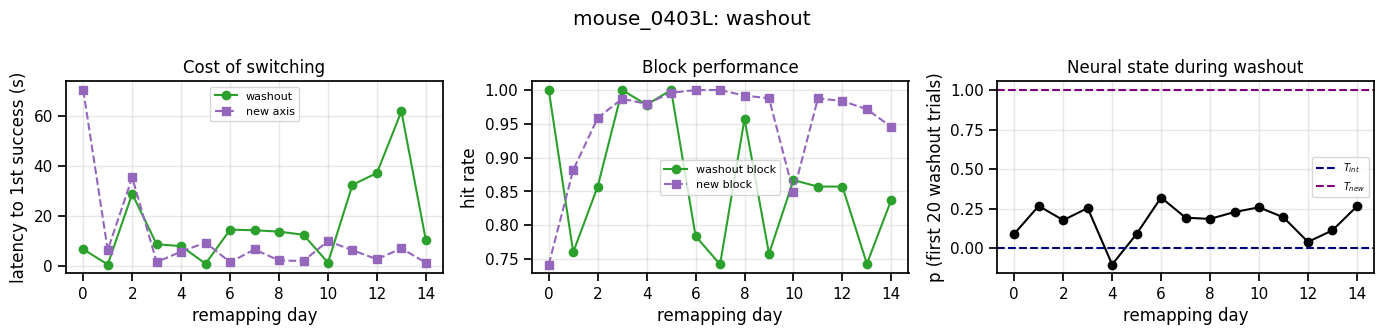

  lat_wash  vs remap day: r=+0.52 p=0.044
  hit_wash  vs remap day: r=-0.41 p=0.129
  lat_new   vs remap day: r=-0.36 p=0.187
  washout p vs remap day: r=+0.07 p=0.800   (mean washout p = +0.17)

READ: washout endpoints sit near p~0, i.e. the animal does recover the OLD solution -- which also
confirms p tracks the solution rather than time in session. But the behavioural cost of getting
there grows across days while new-axis performance stays at ceiling.


In [ ]:
wash = sol_df[(sol_df.block == "washout") & (sol_df.k < 20)]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
axes[0].plot(beh.remap_day, beh.lat_wash, "o-", color="tab:green", label="washout")
axes[0].plot(beh.remap_day, beh.lat_new, "s--", color="tab:purple", label="new axis")
axes[0].set(xlabel="remapping day", ylabel="latency to 1st success (s)", title="Cost of switching"); axes[0].legend(fontsize=8)
axes[1].plot(beh.remap_day, beh.hit_wash, "o-", color="tab:green", label="washout block")
axes[1].plot(beh.remap_day, beh.hit_new, "s--", color="tab:purple", label="new block")
axes[1].set(xlabel="remapping day", ylabel="hit rate", title="Block performance"); axes[1].legend(fontsize=8)
g = wash.groupby("remap_day").p.mean()
axes[2].plot(g.index, g.values, "o-", color="k"); axes[2].axhline(0, color="navy", ls="--", label="$T_{int}$")
axes[2].axhline(1, color="purple", ls="--", label="$T_{new}$")
axes[2].set(xlabel="remapping day", ylabel="p (first 20 washout trials)", title="Neural state during washout"); axes[2].legend(fontsize=7)
for a in axes: a.grid(alpha=0.3)
fig.suptitle(f"{MOUSE}: washout")
fig.tight_layout(); fig.savefig(OUT / "A9_washout.png", dpi=150); plt.show()
for c in ["lat_wash", "hit_wash", "lat_new"]:
    x = beh[["remap_day", c]].dropna(); rho, pv = spearmanr(x.remap_day, x[c]); print(f"  {c:9s} vs remap day: r={rho:+.2f} p={pv:.3f}")
x = g.reset_index().dropna(); rho, pv = spearmanr(x.remap_day, x.p)
print(f"  washout p vs remap day: r={rho:+.2f} p={pv:.3f}   (mean washout p = {g.mean():+.2f})")
print(""); print("READ: washout endpoints sit near p~0, i.e. the animal does recover the OLD solution -- which also")
print("confirms p tracks the solution rather than time in session. But the behavioural cost of getting")
print("there grows across days while new-axis performance stays at ceiling.")

## 10 · Synthesis — what the data actually show

**Behaviour cleanly separates the two regimes.** On the first remapping day the animal needs ~70 s and
several failed trials to regain control (block hit rate 0.74). From day 1 onward it is essentially
correct on the **first** new-axis trial (latency ~7 s, ~0 failures before the first success, hit rate
0.97). Discovery happens once; afterwards the animal *switches*.

**The population leaves the old solution immediately — there is no endpoint perseveration.** Even on
day 0, the first post-rotation trials already sit well away from `T_int` (`p` ≈ 0.75–0.83, close to the
ITI level) rather than at `p ≈ 0`. What distinguishes failures from successes is not a return to the
old solution but **falling short of `T_new`** (day-0 failures `p` = 0.73 vs successes `p` = 0.96).
Day 0 does sit measurably **further off the line joining the two solutions** than later days
(residual 0.97 vs 0.88, MWU p = 6×10⁻⁴) — its activity is closer to *neither* solution. The "search"
is therefore better described as *converging onto* a new endpoint than as *escaping* the old one.

**The post-rotation change is a faster trajectory, not a large-volume random search.** Speed rises
after the rotation, and more so on day 0 than later. But the radius of gyration *falls* on all days,
and the local dimensionality rises *less* on day 0 than on later days. The classic
"exploration = expansion of the explored volume" signature is **not** what this dataset shows at this
timescale.

**Switching on later days is immediate at trial onset.** Aligning to trial start, pre- and
post-rotation trials begin from the *same* self-initiated state (`p` ≈ 0.42). Within ~0.25 s they
commit in **opposite** directions: pre-rotation trials dive toward the intuitive solution
(`p` ≈ 0.12) while post-rotation trials climb toward the new one (`p` ≈ 0.75), with sustained
separation from ~0.17 s. The animal needs neither a failed trial nor even a full trial to register the
change — the very first new-axis trial is already aimed at the new solution, which is why behavioural
latency is ~7 s with essentially no failures. (Caveat: the fixed 8 s window extends past short trials,
pulling both curves toward the baseline level late in the window.)

**The new solution becomes dominant.** Washout endpoints return to `p ≈ 0.1`, confirming the readout
tracks the solution and not time in session — but the behavioural cost of getting back rises across
days (latency r = +0.52, p = 0.044) while new-axis performance stays at ceiling. The animal does not
just find the new solution; it comes to prefer it, at the expense of the previously effortless one.

### Honest limitations and rejected analyses
* Single animal, one within-manifold rotation, one rotation per session at a fixed session time.
* Two readouts were tried and **rejected** as invalid: a 1-D projection alone (the ITI state also
  projects near the "new" end, so it cannot separate "new solution" from "not a solution"), and the
  scale-free index `(d_int−d_new)/(d_int+d_new)` (too insensitive: trial-to-trial variability greatly
  exceeds the template separation in 468-D, so all groups collapsed to |index| < 0.2). The 2-D
  `(p, resid)` decomposition used here is the version that passes the washout and ITI control checks.
* One analysis returned a **null**: trial-to-trial "failure-driven" step size did not differ after
  failures vs successes (Wilcoxon p = 0.77), and it is not estimable on later days, where failures
  are nearly absent.
* `resid` is normalised by a within-day spread, because the raw template separation `L` itself grows
  across days (13.3 → 20.0) and would otherwise confound cross-day comparisons.